Importing libraries:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Load Dataset:

In [2]:
dataset=pd.read_csv("Mall_Customers.csv")

Features Split:

In [3]:
X=dataset.iloc[:,[3,4]].values

Standard Scaler:

In [4]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_scaled=sc.fit_transform(X)

Train a Model:

In [5]:
from sklearn.cluster import DBSCAN
cluster=DBSCAN(eps=0.50, min_samples=5, metric='euclidean', 
               metric_params=None, algorithm='auto', leaf_size=30)
labels=cluster.fit_predict(X_scaled)

Display the Cluster lables:

In [6]:
labels

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
        0,  0,  0,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,
        0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,
        1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,
        0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,  1,  0,
        1,  0,  1,  0, -1, -1,  1, -1, -1, -1, -1, -1, -1])

Create a DataFrame to Existing Dataset:

In [7]:
Clustered_dataset=pd.DataFrame(dataset)

Add Labels to the Existing Dataset:

In [8]:
Clustered_dataset["Clustered_Group"]=labels
Clustered_dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Clustered_Group
0,1,Male,19,15,39,0
1,2,Male,21,15,81,0
2,3,Female,20,16,6,0
3,4,Female,23,16,77,0
4,5,Female,31,17,40,0
...,...,...,...,...,...,...
195,196,Female,35,120,79,-1
196,197,Female,45,126,28,-1
197,198,Male,32,126,74,-1
198,199,Male,32,137,18,-1


Plot the Cluster's Graph:

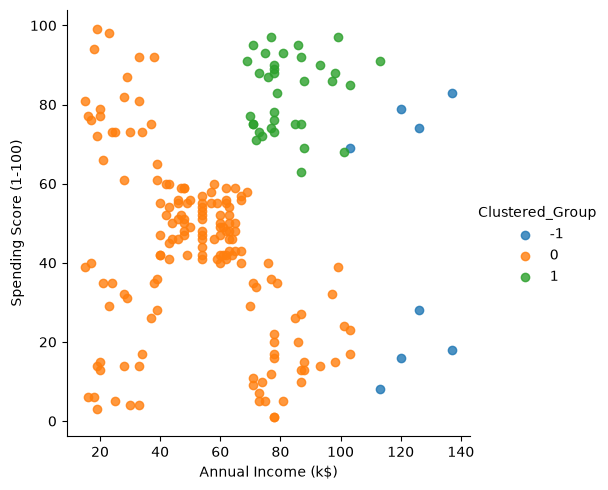

In [9]:
import seaborn as sns
facet=sns.lmplot(data=Clustered_dataset,x=Clustered_dataset.columns[3],y=Clustered_dataset.columns[4],hue=Clustered_dataset.columns[5],fit_reg=False,legend=True)
facet

Evaluation Metrics:

In [10]:
from sklearn.metrics import silhouette_score
score=silhouette_score(X_scaled,labels)
print("The Model Segregated score(-1 to +1) :",score)

The Model Segregated score(-1 to +1) : 0.35044619989666004


Average Annual Income and Spending Score by Cluster for Final Understanding:

In [11]:
cluster_profile=Clustered_dataset.groupby('Clustered_Group')[
    ['Annual Income (k$)','Spending Score (1-100)']
    ].mean()
print(cluster_profile)

                 Annual Income (k$)  Spending Score (1-100)
Clustered_Group                                            
-1                       122.750000               46.875000
 0                        52.490446               43.101911
 1                        82.542857               82.800000


Count the Dataset Lables Based on Uniques:

In [12]:
print(Clustered_dataset['Clustered_Group'].value_counts())

Clustered_Group
 0    157
 1     35
-1      8
Name: count, dtype: int64
